# Reciprocal Ranking for a Dating Feed: Optimizing for Matches, Not Likes

**Author:** Yelyzaveta Zakharova, Product Analyst
**Data:** fully simulated data and simulator of a fictional dating app ("Driftly"). No real company data is used.

**Business question.** The women's feed ranks men by popularity. A like only becomes value when it turns into a **mutual match**,
which needs her like *and* his like back. Would ranking by the probability of a mutual match do better, and what does it do to how attention is spread across men?

**Data.** `impressions.csv.gz`: 14 days of logged feed impressions (875K) from the current popularity ranker, of which 20% are random exploration slots;
`women.csv`, `men.csv`: profile attributes. `sim.py`: the simulator that produced the logs, reused to test new rankers.

**Approach.** Two models (her like; his like-back) → three rankers → offline evaluation on unbiased exploration slots → simulated rollout with a crowded-inbox effect.

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sim import World, NW, NM, POOL

logs = pd.read_csv("data/impressions.csv.gz")
men = pd.read_csv("data/men.csv").rename(columns={"age": "m_age", "photo_score": "m_photo"})
wom = pd.read_csv("data/women.csv").rename(columns={"age": "w_age", "photo_score": "w_photo"})
L = logs.merge(men, on="man_id").merge(wom, on="woman_id")
L["age_gap_abs"] = (L.m_age - L.w_age - 2).abs()
print(f"{len(L):,} impressions; her like rate {L.her_like.mean():.1%}; like-back given her like {L.mutual.sum()/L.her_like.sum():.1%}")

875,000 impressions; her like rate 9.3%; like-back given her like 21.9%


## 1. Where the current feed loses matches
If popular men get most of the attention, they get most of the likes, and they can't (or won't) answer all of them.

In [2]:
tr = L[L.day < 10]
days = tr.day.nunique()
m_stats = tr.groupby("man_id").agg(likes=("her_like", "sum"), mutual=("mutual", "sum"), imp=("her_like", "size"))
m_stats["likes_per_day"] = m_stats.likes / days
m_stats["back_rate"] = m_stats.mutual / m_stats.likes.replace(0, np.nan)
m_stats["load_bucket"] = pd.cut(m_stats.likes_per_day, [-.01, 1, 3, 6, 1000], labels=["≤1", "1–3", "3–6", "6+"])
load_tbl = m_stats.groupby("load_bucket", observed=True).agg(men=("likes", "size"), back_rate=("back_rate", "mean"),
                                                             share_of_likes=("likes", "sum"))
load_tbl["share_of_likes"] /= load_tbl.share_of_likes.sum()
display(load_tbl.round(3))
top10 = m_stats.imp.sort_values(ascending=False); share_top10 = top10.head(int(NM * .1)).sum() / top10.sum()
print(f"Top 10% of men get {share_top10:.0%} of impressions in the logged feed")

,men,back_rate,share_of_likes
load_bucket,,,
≤1,3512,0.397,0.156
1–3,1853,0.241,0.462
3–6,560,0.121,0.309
6+,75,0.046,0.073


Top 10% of men get 16% of impressions in the logged feed


Men who receive many likes answer far fewer of them, and they collect most of the likes. Popularity ranking pours women's likes into the inboxes least likely to answer.

## 2. Two models
- **P(her like)**: his photo score, shared interests, distance, age gap.
- **P(his like-back | her like)**: her photo score, his photo score, shared interests, distance, age gap, and his **recent inbox load** (likes received per day).

Logistic regression on days 0–9 on purpose: it is fast, stable, and its coefficients explain *why* a ranker behaves as it does.

In [3]:
F_HER = ["m_photo", "shared_interests", "distance_km", "age_gap_abs"]
L["load"] = L.man_id.map(m_stats.likes_per_day).fillna(0)
F_HIS = ["w_photo", "m_photo", "shared_interests", "distance_km", "age_gap_abs", "load"]
tr = L[L.day < 10]; te = L[L.day >= 10]
sc_her = StandardScaler().fit(tr[F_HER]); sc_his = StandardScaler().fit(tr.loc[tr.her_like == 1, F_HIS])
m_her = LogisticRegression(max_iter=1000).fit(sc_her.transform(tr[F_HER]), tr.her_like)
liked = tr[tr.her_like == 1]
m_his = LogisticRegression(max_iter=1000).fit(sc_his.transform(liked[F_HIS]), liked.mutual)
coef = pd.concat([pd.Series(m_her.coef_[0], F_HER, name="her_like"), pd.Series(m_his.coef_[0], F_HIS, name="his_like_back")], axis=1)
te_l = te[te.her_like == 1]
print(f"Test AUC: her like {roc_auc_score(te.her_like, m_her.predict_proba(sc_her.transform(te[F_HER]))[:,1]):.3f}; "
      f"his like-back {roc_auc_score(te_l.mutual, m_his.predict_proba(sc_his.transform(te_l[F_HIS]))[:,1]):.3f}")
coef.round(2)

Test AUC: her like 0.718; his like-back 0.689


,her_like,his_like_back
m_photo,0.77,-0.29
shared_interests,0.23,0.27
distance_km,-0.33,-0.10
age_gap_abs,-0.54,-0.26
w_photo,NaN,0.58
load,NaN,-0.56


The two sides want different things. His photo score drives her like up but his like-back **down** (popular men are pickier),
and his inbox load pushes like-back down further. A ranker that only predicts her like can't see either effect.

## 3. Offline evaluation on exploration slots
Logged impressions are biased: the old ranker chose what was shown. The 20% random exploration slots are not, so rankers are compared only there (test days 10–13).
Metric: NDCG@5 with mutual matches as relevance, per woman, with bootstrap CIs over women.

In [4]:
ex = te[te.is_exploration == 1].copy()
ex["s_pop"] = ex.m_photo
ex["s_her"] = m_her.predict_proba(sc_her.transform(ex[F_HER]))[:, 1]
ex["s_his"] = m_his.predict_proba(sc_his.transform(ex[F_HIS]))[:, 1]
ex["s_rec"] = ex.s_her * ex.s_his

def ndcg_at(g, col, k=5):
    rel = g.sort_values(col, ascending=False).mutual.values[:k]
    ideal = np.sort(g.mutual.values)[::-1][:k]
    disc = 1 / np.log2(np.arange(2, k + 2))
    return (rel * disc[:len(rel)]).sum() / (ideal * disc[:len(ideal)]).sum()

has = ex.groupby("woman_id").mutual.transform("sum") > 0
exw = ex[has]
nd = pd.DataFrame({p: exw.groupby("woman_id").apply(lambda g: ndcg_at(g, c)) for p, c in
                   [("Popularity", "s_pop"), ("Her-like model", "s_her"), ("Reciprocal", "s_rec")]})
rng = np.random.default_rng(0)
boots = np.array([nd.iloc[rng.integers(0, len(nd), len(nd))].mean().values for _ in range(1000)])
off = pd.DataFrame({"ndcg5": nd.mean(), "lo": np.percentile(boots, 2.5, 0), "hi": np.percentile(boots, 97.5, 0),
                    "auc_mutual": [roc_auc_score(ex.mutual, ex[c]) for c in ["s_pop", "s_her", "s_rec"]]})
print(f"{len(nd):,} women with at least one mutual in exploration slots")
off.round(3)

430 women with at least one mutual in exploration slots


,ndcg5,lo,hi,auc_mutual
Popularity,0.231,0.203,0.262,0.606
Her-like model,0.362,0.329,0.394,0.735
Reciprocal,0.372,0.338,0.405,0.758


## 4. Simulated rollout
Offline metrics can't capture the crowding effect: changing who is shown changes who gets crowded. So each ranker runs for 7 days in the simulator,
on the same random seed, with the inbox-capacity effect switched on. (This step is only possible because the world is simulated; with real data it would be an A/B test.)

In [5]:
W = World()
mp = W.m_photo[W.pool]; sh = W.shared; di = W.dist; ag = np.abs(W.age_gap - 2)
wp = np.repeat(W.w_photo[:, None], POOL, 1)
ld = m_stats.likes_per_day.reindex(range(NM)).fillna(0).values[W.pool]
X1 = np.stack([mp, sh, di, ag], -1).reshape(-1, 4)
X2 = np.stack([wp, mp, sh, di, ag, ld], -1).reshape(-1, 6)
p_her = m_her.predict_proba(sc_her.transform(pd.DataFrame(X1, columns=F_HER)))[:, 1].reshape(NW, POOL)
p_his = m_his.predict_proba(sc_his.transform(pd.DataFrame(X2, columns=F_HIS)))[:, 1].reshape(NW, POOL)
POL = {"Popularity (current)": mp, "Her-like model": p_her, "Reciprocal": p_her * p_his}

def gini(x):
    s = np.sort(x); n = len(s); return (2 * np.arange(1, n + 1) - n - 1).dot(s) / (n * s.sum())

res, expo = {}, {}
for name, S in POL.items():
    rng = np.random.default_rng(5); seen = np.zeros((NW, POOL), bool)
    o = pd.concat([W.run_day(lambda d: S, seen, rng, d) for d in range(7)])
    e = np.bincount(o.man_id, minlength=NM); mu = np.bincount(o.man_id[o.mutual == 1], minlength=NM)
    wm = o.groupby("woman_id").mutual.sum()
    res[name] = dict(her_like_rate=o.her_like.mean(), like_back_rate=o.mutual.sum() / o.her_like.sum(),
                     mutual_per_100=o.mutual.mean() * 100, mutual_per_woman_week=wm.mean(),
                     women_with_mutual=(wm > 0).mean(), exposure_gini=gini(e), men_unseen=(e == 0).mean(),
                     men_with_mutual=(mu > 0).mean(), top10_share=np.sort(e)[::-1][:NM // 10].sum() / e.sum())
    expo[name] = np.sort(e)
sim = pd.DataFrame(res).T
base = sim.loc["Her-like model"]
print(f"Reciprocal vs her-like model: mutuals {sim.loc['Reciprocal','mutual_per_100']/base.mutual_per_100-1:+.0%}, "
      f"her likes {sim.loc['Reciprocal','her_like_rate']/base.her_like_rate-1:+.0%}; "
      f"vs popularity: mutuals {sim.loc['Reciprocal','mutual_per_100']/sim.iloc[0].mutual_per_100-1:+.0%}")
sim.round(3)

Reciprocal vs her-like model: mutuals +14%, her likes -13%; vs popularity: mutuals +95%


,her_like_rate,like_back_rate,mutual_per_100,mutual_per_woman_week,women_with_mutual,exposure_gini,men_unseen,men_with_mutual,top10_share
Popularity (current),0.149,0.130,1.928,3.374,0.876,0.518,0.434,0.473,0.222
Her-like model,0.158,0.209,3.294,5.765,0.950,0.417,0.084,0.704,0.209
Reciprocal,0.137,0.276,3.763,6.585,0.964,0.255,0.004,0.794,0.176


## 5. Conclusions

1. **Popularity ranking wastes women's likes.** It sends them to the men least likely to answer, so only a small share turns into matches.
2. **Modeling her preference is a big step; modeling both sides is a bigger one.** The reciprocal ranker gives the most mutual matches,
   at the cost of a slightly lower like rate. Likes are a proxy; matches are the value.
3. **Attention spreads out.** Almost every man gets seen and many more men get at least one match, which matters for men's retention too.
4. **Next step:** an online A/B test with mutual matches per woman as the primary metric and her like rate, women's retention and reports as guardrails;
   and a load-aware term so the ranker adapts to inbox crowding in real time.

## Charts

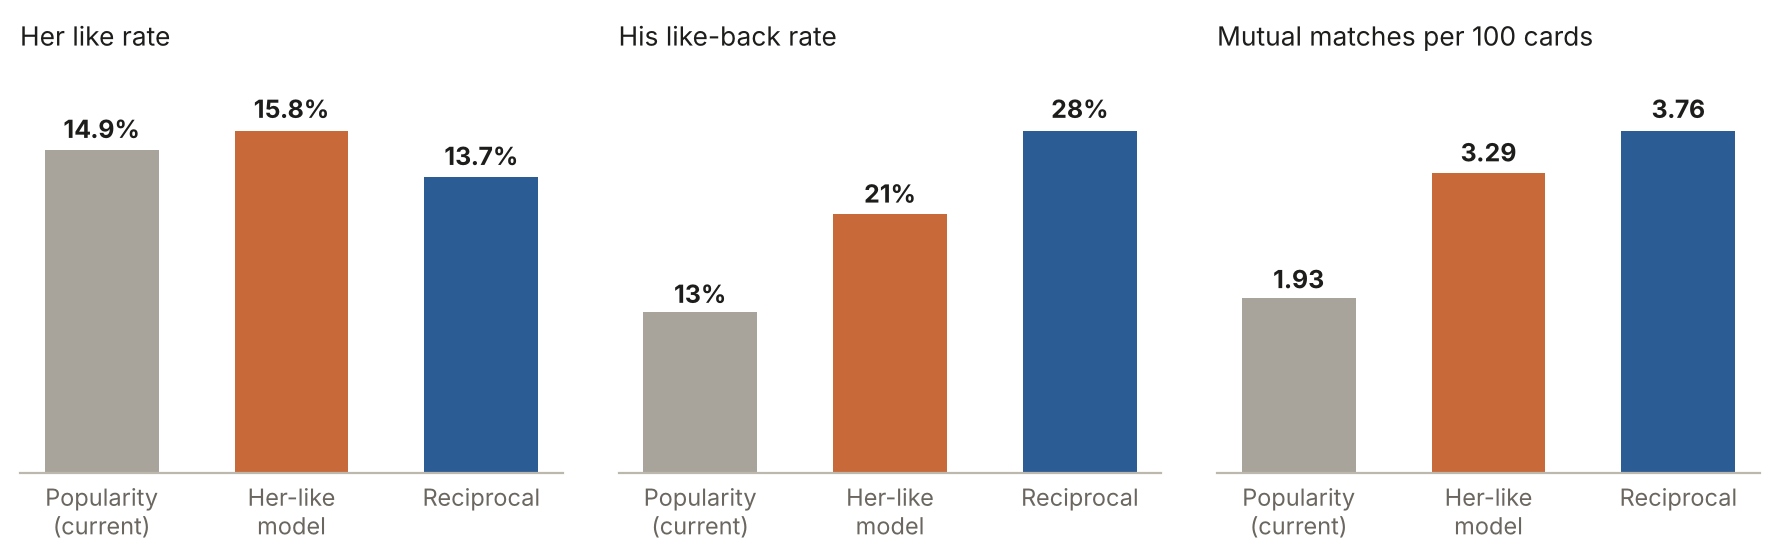

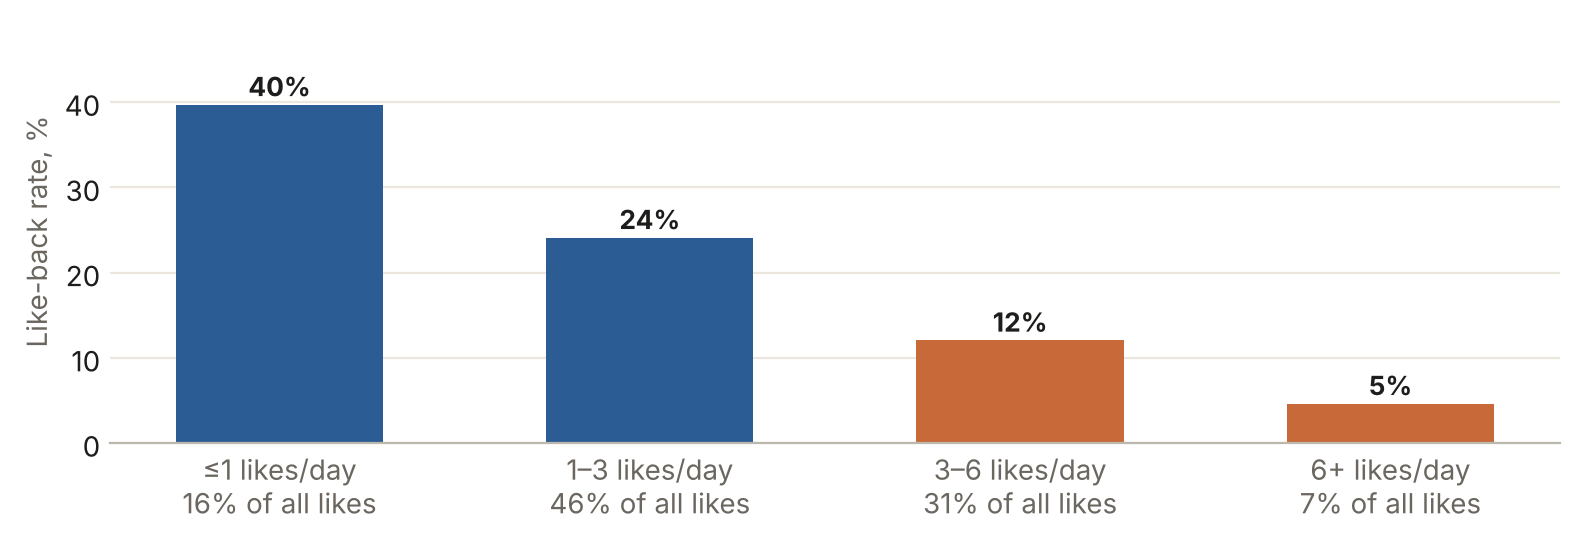

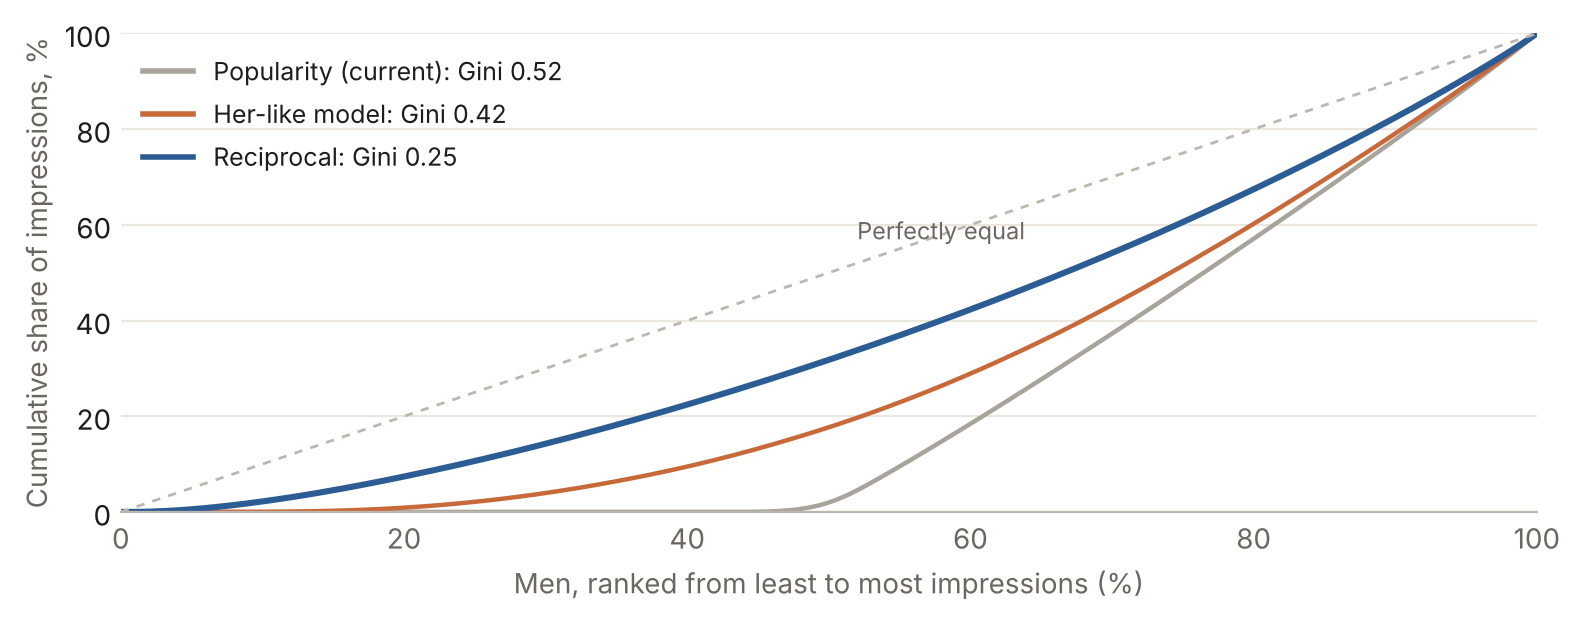

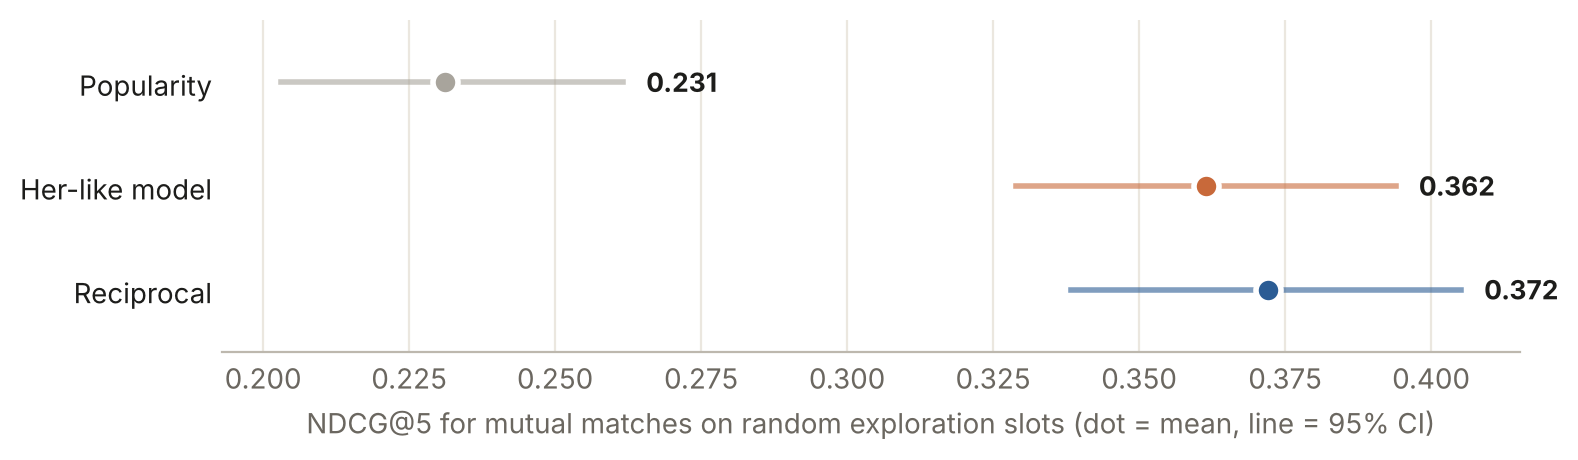

In [6]:
W_, M_, INK, INK2, RULE, GRID, OTHER = "#2b5c94", "#c8693a", "#1d1d1b", "#6b6760", "#bdb8ae", "#ebe7df", "#a8a49c"
plt.rcParams.update({"font.family": "Inter", "font.size": 10, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": RULE, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK, "xtick.major.size": 0, "ytick.major.size": 0, "savefig.transparent": True})
COL = {"Popularity (current)": OTHER, "Her-like model": M_, "Reciprocal": W_}
SHORT = {"Popularity (current)": "Popularity\n(current)", "Her-like model": "Her-like\nmodel", "Reciprocal": "Reciprocal"}

# E1 funnel by policy
fig, axes = plt.subplots(1, 3, figsize=(9, 2.9))
for ax, (col, lab, f) in zip(axes, [("her_like_rate", "Her like rate", lambda v: f"{v*100:.1f}%"),
                                    ("like_back_rate", "His like-back rate", lambda v: f"{v*100:.0f}%"),
                                    ("mutual_per_100", "Mutual matches per 100 cards", lambda v: f"{v:.2f}")]):
    for i, (p, r) in enumerate(sim.iterrows()):
        v = r[col] * (100 if col != "mutual_per_100" else 1)
        ax.bar(i, v, color=COL[p], width=.6); ax.text(i, v * 1.02, f(r[col]), ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_xticks(range(3), [SHORT[p] for p in sim.index], fontsize=8.5); ax.set_title(lab, loc="left", fontsize=9.5)
    ax.set_yticks([]); ax.set_ylim(0, sim[col].max() * (100 if col != "mutual_per_100" else 1) * 1.2)
    ax.spines["bottom"].set_color(RULE)
fig.tight_layout(w_pad=2); fig.savefig("charts/e1_funnel.png", dpi=240)

# E2 like-back vs load
lt = load_tbl.reset_index()
fig, ax = plt.subplots(figsize=(8, 2.8))
x = np.arange(len(lt))
ax.bar(x, lt.back_rate * 100, color=[W_, W_, M_, M_], width=.56)
for xi, r in zip(x, lt.itertuples()):
    ax.text(xi, r.back_rate * 100 + 1, f"{r.back_rate*100:.0f}%", ha="center", fontsize=9.5, fontweight="bold")
ax.set_xticks(x, [f"{b} likes/day\n{r.share_of_likes*100:.0f}% of all likes" for b, r in zip(lt.load_bucket, lt.itertuples())])
ax.set_ylabel("Like-back rate, %"); ax.set_ylim(0, lt.back_rate.max() * 100 * 1.25)
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e2_load.png", dpi=240)

# E3 Lorenz curves of exposure
fig, ax = plt.subplots(figsize=(8, 3.2))
for p, e in expo.items():
    c = np.cumsum(e) / e.sum(); xs = np.linspace(0, 100, len(c))
    ax.plot(xs, c * 100, color=COL[p], lw=2.2 if p == "Reciprocal" else 1.6)
ax.plot([0, 100], [0, 100], color=RULE, lw=1, ls=(0, (3, 3)))
ax.text(52, 57, "Perfectly equal", color=INK2, fontsize=8.5, rotation=0)
ax.legend([plt.Line2D([], [], color=COL[p], lw=2) for p in expo],
          [f"{p}: Gini {sim.loc[p,'exposure_gini']:.2f}" for p in expo], frameon=False, loc="upper left", fontsize=9)
ax.set_xlabel("Men, ranked from least to most impressions (%)"); ax.set_ylabel("Cumulative share of impressions, %")
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
fig.tight_layout(); fig.savefig("charts/e3_lorenz.png", dpi=240)

# E4 offline NDCG
fig, ax = plt.subplots(figsize=(8, 2.4))
y = np.arange(3)[::-1]
for yi, (p, r) in zip(y, off.iterrows()):
    c = {"Popularity": OTHER, "Her-like model": M_, "Reciprocal": W_}[p]
    ax.plot([r.lo, r.hi], [yi, yi], color=c, lw=2, alpha=.6); ax.plot(r.ndcg5, yi, "o", color=c, ms=9, mec="white", mew=2)
    ax.text(r.hi + .004, yi, f"{r.ndcg5:.3f}", va="center", fontsize=9.5, fontweight="bold")
ax.set_ylim(-0.6, 2.6); ax.set_yticks(y, off.index); ax.set_xlabel("NDCG@5 for mutual matches on random exploration slots (dot = mean, line = 95% CI)")
ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e4_offline.png", dpi=240)
plt.show()

In [7]:
out = dict(n_imp=len(L), load=load_tbl.reset_index().astype({"load_bucket": str}).to_dict("records"), share_top10=share_top10,
           coef=coef.to_dict(), off=off.to_dict("index"), sim=sim.to_dict("index"), n_women_eval=len(nd),
           logged=dict(her_like=L.her_like.mean(), back=L.mutual.sum() / L.her_like.sum()))
json.dump(out, open("results.json", "w"), default=float, indent=1)